# Atividade Prática — Redução de Dimensionalidade e Pipeline de Agrupamento


## Contexto
A HELP International é uma ONG humanitária que arrecadou US$ 10 milhões para ações de combate à pobreza e de apoio em situações de desastre. A direção precisa decidir como distribuir esses recursos entre os países e solicitou à equipe de dados uma classificação dos países em **três níveis**, com base em indicadores socioeconômicos e de saúde.

## Objetivo
Aplicar a Análise de Componentes Principais (PCA) a uma base real e construir um *pipeline* de padronização, redução de dimensionalidade e agrupamento (K-Means), avaliando o efeito de cada etapa sobre o resultado.

## Dados
Base *Unsupervised Learning on Country Data*, disponível no Kaggle: 167 países e 9 indicadores. Os dados já estão carregados neste notebook.

## Entregável
1. Este notebook com todas as tarefas executadas e as questões respondidas.
2. O arquivo `modelo_paises.pkl`, gerado na Parte 7, que será utilizado na aula de implantação.

## Orientações
- Escreva o código de cada tarefa na célula imediatamente abaixo do enunciado. Crie novas células sempre que necessário.
- Responda às questões discursivas nas células de texto indicadas, com base nos resultados obtidos.
- Respeite os nomes de variáveis solicitados nos enunciados.
- Não altere o DataFrame original `df`.
- Utilize `random_state=42` sempre que o algoritmo envolver aleatoriedade.

In [1]:
# @title Configuração do ambiente (célula fornecida)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.pipeline import make_pipeline
import joblib

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rohan0301/unsupervised-learning-on-country-data")

print("Path to dataset files:", path)

df = pd.read_csv(path+"/Country-data.csv")
print(f"Base carregada: {df.shape[0]} linhas e {df.shape[1]} colunas.")

/tmp/claude-1000/-home-joao--claude-spares-spare-HYADfB/2b1ef5da-85fe-4814-aa96-722b386fc4d7/scratchpad/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: /home/joao/.cache/kagglehub/datasets/rohan0301/unsupervised-learning-on-country-data/versions/2
Base carregada: 167 linhas e 10 colunas.


### Dicionário de dados

| Coluna | Significado |
|---|---|
| `country` | nome do país |
| `child_mort` | mortes de crianças menores de 5 anos a cada 1.000 nascidos vivos |
| `exports` | exportações de bens e serviços per capita, em % do PIB per capita |
| `health` | gasto total com saúde per capita, em % do PIB per capita |
| `imports` | importações de bens e serviços per capita, em % do PIB per capita |
| `income` | renda líquida por pessoa (US$) |

| Coluna | Significado |
|---|---|
| `inflation` | taxa anual de crescimento do PIB total, em % (indicador de inflação) |
| `life_expec` | expectativa de vida ao nascer, em anos |
| `total_fer` | número médio de filhos por mulher |
| `gdpp` | PIB per capita (US$) |

## Parte 1 — Preparação e análise das escalas

**Tarefa 1.1.** Crie a variável `X`, contendo apenas os indicadores numéricos, e a variável `paises`, contendo os nomes dos países na mesma ordem das linhas de `X`. Verifique se há valores ausentes.

**Tarefa 1.2.** Apresente, para cada indicador, a média, o desvio padrão, o mínimo e o máximo.

In [3]:
# Tarefas 1.1 e 1.2
# 1.1 — variáveis X (indicadores numéricos) e paises (nomes, mesma ordem)
X = df.drop(columns="country")
paises = df["country"]

print("Dimensões de X:", X.shape)
print("\nValores ausentes por coluna:")
print(X.isna().sum())
print("\nTotal de valores ausentes:", X.isna().sum().sum())

# 1.2 — média, desvio padrão, mínimo e máximo de cada indicador
resumo = X.agg(["mean", "std", "min", "max"]).T
resumo.columns = ["média", "desvio padrão", "mínimo", "máximo"]
resumo.sort_values("desvio padrão", ascending=False).round(2)

Dimensões de X: (167, 9)

Valores ausentes por coluna:
child_mort    0
exports       0
health        0
imports       0
income        0
inflation     0
life_expec    0
total_fer     0
gdpp          0
dtype: int64

Total de valores ausentes: 0


,média,desvio padrão,mínimo,máximo
income,17144.69,19278.07,609.00,125000.00
gdpp,12964.16,18328.70,231.00,105000.00
child_mort,38.27,40.33,2.60,208.00
exports,41.11,27.41,0.11,200.00
imports,46.89,24.21,0.07,174.00
inflation,7.78,10.57,-4.21,104.00
life_expec,70.56,8.89,32.10,82.80
health,6.82,2.75,1.81,17.90
total_fer,2.95,1.51,1.15,7.49


**Questão 1.** Quais indicadores apresentam as maiores escalas numéricas? Que efeito você espera que essa diferença de escala produza sobre o PCA?

**Resposta:** Os indicadores monetários `income` (desvio padrão ≈ 19.278, máximo de 125.000) e `gdpp` (desvio padrão ≈ 18.329, máximo de 105.000) têm escalas milhares de vezes maiores que os demais. Em seguida vêm `child_mort`, `exports` e `imports` (desvios entre 24 e 40), enquanto `health` (≈ 2,7) e `total_fer` (≈ 1,5) variam muito pouco em termos absolutos.

Como o PCA busca as direções de **maior variância**, e a variância depende da unidade de medida, espera-se que, sem padronização, a PC1 seja praticamente dominada por `income` e `gdpp`: ela "explicará" quase toda a variância simplesmente porque essas colunas são medidas em dólares, e não porque carregam mais informação. Os indicadores de saúde e demografia praticamente não contribuiriam para os componentes.

## Parte 2 — Efeito da padronização

**Tarefa 2.1.** Aplique o PCA a `X` **sem** padronização. Informe a proporção da variância explicada pela PC1 e os pesos (*loadings*) de cada indicador nesse componente.

**Tarefa 2.2.** Padronize `X`, armazenando o resultado em `X_pad`, e repita a análise da Tarefa 2.1.

In [4]:
# Tarefas 2.1 e 2.2
# 2.1 — PCA sem padronização
pca_bruto = PCA(random_state=42).fit(X)
print(f"PCA SEM padronização — variância explicada pela PC1: {pca_bruto.explained_variance_ratio_[0]:.2%}")
loadings_bruto = pd.Series(pca_bruto.components_[0], index=X.columns, name="PC1 (sem padronização)")

# 2.2 — padronização e PCA
scaler = StandardScaler()
X_pad = scaler.fit_transform(X)
pca_pad = PCA(random_state=42).fit(X_pad)
print(f"PCA COM padronização — variância explicada pela PC1: {pca_pad.explained_variance_ratio_[0]:.2%}")
loadings_pad = pd.Series(pca_pad.components_[0], index=X.columns, name="PC1 (com padronização)")

pd.concat([loadings_bruto, loadings_pad], axis=1).round(4)

PCA SEM padronização — variância explicada pela PC1: 94.79%
PCA COM padronização — variância explicada pela PC1: 45.95%


,PC1 (sem padronização),PC1 (com padronização)
child_mort,-0.0008,-0.4195
exports,0.0005,0.2839
health,0.0000,0.1508
imports,0.0001,0.1615
income,0.7267,0.3984
inflation,-0.0001,-0.1932
life_expec,0.0002,0.4258
total_fer,-0.0000,-0.4037
gdpp,0.6869,0.3926


**Questão 2.** Compare os dois resultados. Por que a PCA sem padronização não é adequada para esta base?

**Resposta:** Sem padronização, a PC1 explica **94,8%** da variância, mas seus pesos são praticamente apenas `income` (0,727) e `gdpp` (0,687); todos os outros indicadores têm peso próximo de zero (|peso| < 0,001). Ou seja, o "componente principal" é só uma combinação das duas colunas em dólar.

Com padronização, a PC1 explica **46,0%** da variância e todos os indicadores participam de forma equilibrada: `life_expec` (+0,43), `income` (+0,40), `gdpp` (+0,39) e `exports` (+0,28) de um lado, e `child_mort` (−0,42), `total_fer` (−0,40) e `inflation` (−0,19) do outro.

A PCA sem padronização não é adequada porque os indicadores estão em unidades diferentes (dólares, %, anos, filhos por mulher, mortes por mil). A variância alta de `income` e `gdpp` é um artefato da unidade de medida, e não um sinal de maior importância. O resultado ignoraria mortalidade infantil, expectativa de vida e fecundidade, que são justamente centrais para uma ONG humanitária. A padronização coloca todos os indicadores com média 0 e desvio 1, de modo que o PCA passa a capturar a **estrutura de correlação** entre eles.

## Parte 3 — Número de componentes

**Tarefa 3.1.** A partir de `X_pad`, construa um gráfico com a variância explicada por componente e a variância acumulada.

**Tarefa 3.2.** Determine quantos componentes são necessários para preservar 80% e 90% da variância e confirme os valores utilizando `PCA(n_components=0.8)` e `PCA(n_components=0.9)`.

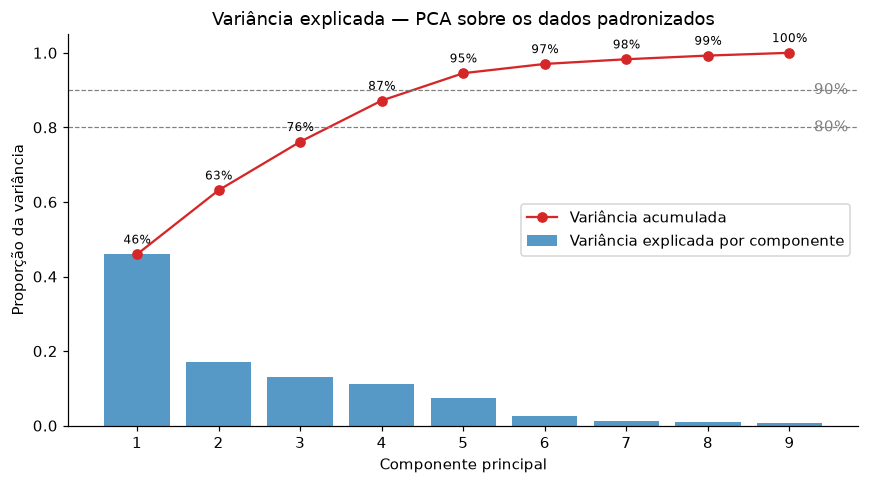

     variância  acumulada
PC1     0.4595     0.4595
PC2     0.1718     0.6313
PC3     0.1300     0.7614
PC4     0.1105     0.8719
PC5     0.0734     0.9453
PC6     0.0248     0.9702
PC7     0.0126     0.9828
PC8     0.0098     0.9926
PC9     0.0074     1.0000

Pela variância acumulada: 4 componentes para 80% e 5 componentes para 90%.
PCA(n_components=0.8) -> 4 componentes (87.19% da variância)
PCA(n_components=0.9) -> 5 componentes (94.53% da variância)


In [5]:
# Tarefas 3.1 e 3.2
var_exp = pca_pad.explained_variance_ratio_
var_acum = np.cumsum(var_exp)
comp = np.arange(1, len(var_exp) + 1)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(comp, var_exp, color="tab:blue", alpha=0.75, label="Variância explicada por componente")
ax.plot(comp, var_acum, "o-", color="tab:red", label="Variância acumulada")
for limiar in (0.8, 0.9):
    ax.axhline(limiar, ls="--", color="gray", lw=0.8)
    ax.text(len(comp) + 0.3, limiar, f"{limiar:.0%}", va="center", color="gray")
for x, y in zip(comp, var_acum):
    ax.annotate(f"{y:.0%}", (x, y), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
ax.set_xticks(comp)
ax.set_xlabel("Componente principal")
ax.set_ylabel("Proporção da variância")
ax.set_title("Variância explicada — PCA sobre os dados padronizados")
ax.legend(loc="center right")
plt.tight_layout()
plt.show()

print(pd.DataFrame({"variância": var_exp, "acumulada": var_acum}, index=[f"PC{i}" for i in comp]).round(4))

# 3.2 — número de componentes para 80% e 90%
n80 = int(np.argmax(var_acum >= 0.8) + 1)
n90 = int(np.argmax(var_acum >= 0.9) + 1)
print(f"\nPela variância acumulada: {n80} componentes para 80% e {n90} componentes para 90%.")

pca80 = PCA(n_components=0.8, random_state=42).fit(X_pad)
pca90 = PCA(n_components=0.9, random_state=42).fit(X_pad)
print(f"PCA(n_components=0.8) -> {pca80.n_components_} componentes ({pca80.explained_variance_ratio_.sum():.2%} da variância)")
print(f"PCA(n_components=0.9) -> {pca90.n_components_} componentes ({pca90.explained_variance_ratio_.sum():.2%} da variância)")

**Questão 3.** Quantos componentes você utilizaria para (a) visualizar os países em um gráfico e (b) alimentar o algoritmo de agrupamento? Justifique cada escolha.

**Resposta:**

**(a) Visualização: 2 componentes.** Um gráfico de dispersão só é legível em duas dimensões, e PC1 + PC2 preservam 63,1% da variância, o suficiente para enxergar o padrão geral (o eixo de desenvolvimento e a abertura comercial) e identificar países extremos. Um terceiro componente (76,1%) até poderia ser usado em gráfico 3D, mas com perda de legibilidade.

**(b) Agrupamento: 5 componentes (90% da variância, 94,5% na prática).** Para o K-Means interessa preservar o máximo de informação descartando apenas o ruído. Os 4 componentes do critério de 80% (87,2%) também seriam razoáveis, mas a PC5 ainda carrega 7,3% da variância, enquanto da PC6 em diante cada componente traz menos de 2,5% (o "cotovelo" do gráfico). Assim, 5 componentes reduzem a dimensão de 9 para 5 praticamente sem perda de estrutura, o que se confirma na Parte 5: o agrupamento com 5 componentes é idêntico ao obtido com os 9 indicadores padronizados.

## Parte 4 — Interpretação dos componentes

**Tarefa 4.1.** Apresente uma tabela com os pesos dos indicadores nos três primeiros componentes, armazenada na variável `pesos`.

**Tarefa 4.2.** Construa um gráfico de dispersão de todos os países no plano PC1 × PC2, destacando e rotulando, no mínimo: Brazil, Norway, United States, India, Niger, Haiti, Singapore e Luxembourg.

,PC1,PC2,PC3
child_mort,-0.420000,0.193000,-0.030000
exports,0.284000,0.613000,0.145000
health,0.151000,-0.243000,-0.597000
imports,0.161000,0.672000,-0.300000
income,0.398000,0.023000,0.302000
inflation,-0.193000,-0.008000,0.643000
life_expec,0.426000,-0.223000,0.114000
total_fer,-0.404000,0.155000,0.020000
gdpp,0.393000,-0.046000,0.123000


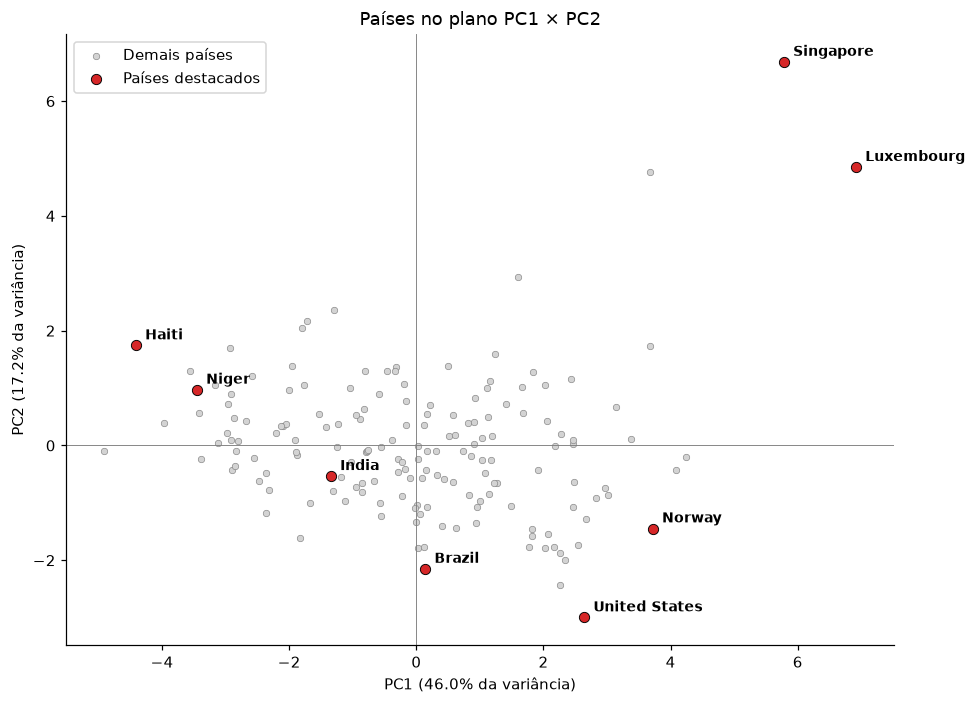

                PC1   PC2
country                  
Brazil         0.14 -2.15
Haiti         -4.41  1.74
India         -1.34 -0.54
Luxembourg     6.92  4.85
Niger         -3.45  0.97
Norway         3.72 -1.45
Singapore      5.78  6.68
United States  2.64 -3.00


In [6]:
# Tarefas 4.1 e 4.2
# 4.1 — pesos dos indicadores nos três primeiros componentes
pesos = pd.DataFrame(pca_pad.components_[:3].T, index=X.columns, columns=["PC1", "PC2", "PC3"])
display(pesos.round(3).style.background_gradient(cmap="RdBu_r", vmin=-0.7, vmax=0.7))

# 4.2 — dispersão dos países no plano PC1 x PC2
scores = pca_pad.transform(X_pad)
destaques = ["Brazil", "Norway", "United States", "India", "Niger", "Haiti", "Singapore", "Luxembourg"]
mask = paises.isin(destaques).values

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.scatter(scores[~mask, 0], scores[~mask, 1], s=18, color="lightgray", edgecolor="gray", lw=0.4, label="Demais países")
ax.scatter(scores[mask, 0], scores[mask, 1], s=45, color="tab:red", edgecolor="black", lw=0.6, label="Países destacados")
for i in np.where(mask)[0]:
    ax.annotate(paises.iloc[i], (scores[i, 0], scores[i, 1]), textcoords="offset points",
                xytext=(6, 4), fontsize=9, fontweight="bold")
ax.axhline(0, color="gray", lw=0.6)
ax.axvline(0, color="gray", lw=0.6)
ax.set_xlabel(f"PC1 ({pca_pad.explained_variance_ratio_[0]:.1%} da variância)")
ax.set_ylabel(f"PC2 ({pca_pad.explained_variance_ratio_[1]:.1%} da variância)")
ax.set_title("Países no plano PC1 × PC2")
ax.legend()
plt.tight_layout()
plt.show()

print(pd.DataFrame(scores[mask, :2], index=paises[mask], columns=["PC1", "PC2"]).round(2))

**Questão 4.** Com base nos pesos, atribua um nome interpretativo à PC1 e à PC2, justificando com os indicadores de maior peso positivo e negativo.

**Resposta:**

**PC1: "Nível de desenvolvimento socioeconômico" (ou "riqueza e saúde").** Pesos positivos mais altos: `life_expec` (+0,43), `income` (+0,40), `gdpp` (+0,39) e `exports` (+0,28). Pesos negativos mais altos: `child_mort` (−0,42), `total_fer` (−0,40) e `inflation` (−0,19). Valores altos de PC1 indicam países ricos, com alta expectativa de vida e baixa mortalidade infantil e fecundidade; valores baixos indicam o oposto. É o eixo "pobreza ↔ prosperidade", o mais relevante para a ONG.

**PC2: "Abertura comercial" (ou "integração ao comércio exterior").** Pesos positivos dominantes: `imports` (+0,67) e `exports` (+0,61). Negativos: `health` (−0,24) e `life_expec` (−0,22). Valores altos de PC2 indicam economias muito abertas, em que exportações e importações representam uma fração enorme do PIB (típico de pequenos países-entreposto). Valores baixos indicam economias mais fechadas ou de grande mercado interno, frequentemente com gasto relativo em saúde mais alto.

**Questão 5.** Interprete a posição do Brasil no gráfico. Em seguida, explique por que Singapore e Luxembourg aparecem afastados dos demais países.

**Resposta:** O **Brasil** está em PC1 ≈ 0,14 e PC2 ≈ −2,15. Em PC1 está praticamente no centro da distribuição, ou seja, é um país de **desenvolvimento intermediário**: indicadores de renda, mortalidade infantil e expectativa de vida próximos da média mundial da base (melhores que os de Índia, Níger ou Haiti, mas bem abaixo dos de Noruega e Estados Unidos). Em PC2 tem valor bastante negativo, o que reflete uma **economia relativamente fechada**: exportações e importações representam uma parcela pequena do PIB, característica de países grandes e com mercado interno extenso (posição semelhante à dos Estados Unidos, que também tem PC2 muito negativo).

**Singapore** (PC1 ≈ 5,8; PC2 ≈ 6,7) e **Luxembourg** (PC1 ≈ 6,9; PC2 ≈ 4,9) ficam afastados porque são extremos **nos dois eixos ao mesmo tempo**. São muito ricos e saudáveis (renda de 72 mil e 92 mil dólares, PIB per capita de 47 mil e 105 mil, máximo da base no caso de Luxembourg, e mortalidade infantil de 2,8), o que os empurra para a direita em PC1. Além disso, têm exportações e importações acima de 140% do PIB (Singapore tem os máximos da base: 200% e 174%), algo atípico, característico de pequenos centros financeiros e logísticos com pouca área e grande fluxo de reexportação, o que os eleva muito em PC2. Nenhum outro país combina esses dois perfis com essa intensidade (apenas Malta se aproxima).

## Parte 5 — Pipeline de agrupamento

**Tarefa 5.1.** Construa um *pipeline* denominado `modelo`, composto por `StandardScaler`, `PCA(n_components=0.9)` e `KMeans(n_clusters=3, n_init=10, random_state=42)`. Ajuste-o sobre `X` (dados originais, sem padronização prévia) e armazene os grupos na variável `grupos`. Informe quantos componentes o PCA utilizou dentro do pipeline.

**Tarefa 5.2.** Compare `grupos` com o resultado de três variações, utilizando o índice de Rand ajustado (`adjusted_rand_score`) e o tamanho de cada grupo:
- (a) K-Means sobre `X_pad`, sem PCA;
- (b) o mesmo pipeline com `PCA(n_components=2)`;
- (c) K-Means sobre `X`, sem padronização e sem PCA.

In [7]:
# Tarefas 5.1 e 5.2
# 5.1 — pipeline completo ajustado sobre os dados originais
modelo = make_pipeline(
    StandardScaler(),
    PCA(n_components=0.9, random_state=42),
    KMeans(n_clusters=3, n_init=10, random_state=42),
)
grupos = modelo.fit_predict(X)
print(f"Componentes utilizados pelo PCA dentro do pipeline: {modelo.named_steps['pca'].n_components_}")
print("Tamanho dos grupos (pipeline):", dict(pd.Series(grupos).value_counts().sort_index()))

# 5.2 — variações
km = lambda: KMeans(n_clusters=3, n_init=10, random_state=42)

g_a = km().fit_predict(X_pad)                                                         # (a) X_pad sem PCA
g_b = make_pipeline(StandardScaler(), PCA(n_components=2, random_state=42), km()).fit_predict(X)  # (b) PCA com 2 componentes
g_c = km().fit_predict(X)                                                             # (c) sem padronização e sem PCA

def tamanhos(g):
    return sorted(pd.Series(g).value_counts().tolist(), reverse=True)

comparacao = pd.DataFrame({
    "variação": ["Pipeline (Scaler + PCA 90% + KMeans)",
                 "(a) KMeans sobre X_pad, sem PCA",
                 "(b) Pipeline com PCA(n_components=2)",
                 "(c) KMeans sobre X, sem padronização e sem PCA"],
    "ARI vs. grupos": [adjusted_rand_score(grupos, g) for g in (grupos, g_a, g_b, g_c)],
    "tamanho dos grupos": [tamanhos(g) for g in (grupos, g_a, g_b, g_c)],
}).set_index("variação")
comparacao.round(3)

Componentes utilizados pelo PCA dentro do pipeline: 5
Tamanho dos grupos (pipeline): {0: np.int64(36), 1: np.int64(84), 2: np.int64(47)}


,ARI vs. grupos,tamanho dos grupos
variação,,
Pipeline (Scaler + PCA 90% + KMeans),1.000,"[84, 47, 36]"
"(a) KMeans sobre X_pad, sem PCA",1.000,"[84, 47, 36]"
(b) Pipeline com PCA(n_components=2),0.318,"[92, 72, 3]"
"(c) KMeans sobre X, sem padronização e sem PCA",0.390,"[128, 32, 7]"


**Questão 6.** Interprete os três resultados. Em particular, explique por que 2 componentes são adequados para visualizar os países, mas alteram significativamente o agrupamento.

**Resposta:**

**(a) K-Means sobre `X_pad`, sem PCA: ARI = 1,00**, grupos idênticos (84, 47, 36). Os 5 componentes preservam 94,5% da variância, e os 4 descartados contêm basicamente ruído, então as distâncias entre países praticamente não mudam e o K-Means encontra exatamente a mesma partição. O PCA de 90% simplificou a representação sem prejudicar o agrupamento.

**(b) Pipeline com `PCA(n_components=2)`: ARI ≈ 0,32**, grupos de tamanhos (92, 72, 3). O agrupamento muda bastante: um grupo passa a conter só Luxembourg, Malta e Singapore (os extremos de PC2), e os demais países ricos se juntam aos de renda média.

**(c) K-Means sobre `X` sem padronização e sem PCA: ARI ≈ 0,39**, grupos (128, 32, 7). Como as distâncias são dominadas por `income` e `gdpp`, o K-Means apenas fatia os países por renda: um grupo de 7 países riquíssimos (Brunei, Kuwait, Luxembourg, Norway, Qatar, Singapore, Switzerland) e um grupo enorme de 128 países que mistura situações críticas com países de renda média. Mortalidade infantil e expectativa de vida são ignoradas, o que torna esse resultado inútil para a ONG.

**Por que 2 componentes servem para visualizar, mas alteram o agrupamento?** Para visualização, o objetivo é dar ao olho humano um resumo aproximado: 63% da variância basta para enxergar a tendência geral e os extremos, e a distorção é aceitável. O K-Means, porém, decide tudo a partir das **distâncias exatas** entre os pontos. Ao descartar a PC3, a PC4 e a PC5 (cerca de 31% da variância, incluindo informações de `inflation`, `health` e `income` que não estão nas duas primeiras), países que eram diferentes passam a parecer próximos. Além disso, a PC2 (abertura comercial) ganha peso relativo muito maior no espaço reduzido, e por isso o algoritmo gasta um grupo inteiro com os 3 países-entreposto, separados por comércio exterior e não por condição socioeconômica. Uma representação boa para o olho não é necessariamente fiel o bastante para um algoritmo baseado em distâncias.

**Tarefa 5.3.** Calcule o coeficiente de silhueta para k de 2 a 6, aplicando o K-Means sobre os dados já padronizados e reduzidos pelo PCA do pipeline (dica de API: `modelo[:-1].transform(X)` aplica todas as etapas exceto a última).

Dimensões dos dados reduzidos: (167, 5)
2    0.3044
3    0.3080
4    0.3287
5    0.3305
6    0.2560
Name: silhueta, dtype: float64


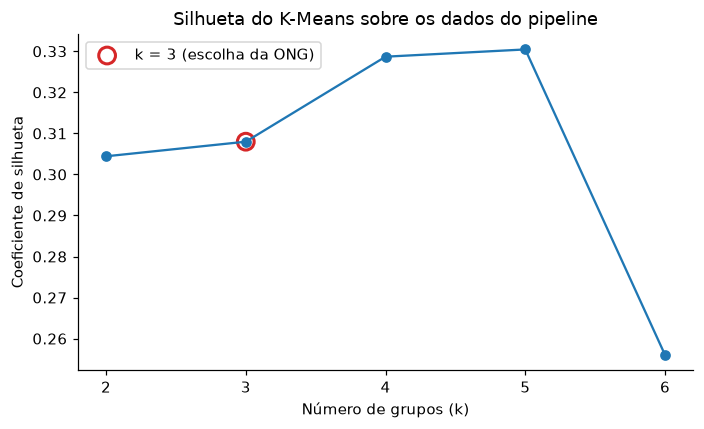

In [8]:
# Tarefa 5.3
X_red = modelo[:-1].transform(X)   # dados padronizados e reduzidos pelo PCA do pipeline
print("Dimensões dos dados reduzidos:", X_red.shape)

silhuetas = {}
for k in range(2, 7):
    rotulos = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_red)
    silhuetas[k] = silhouette_score(X_red, rotulos)
silhuetas = pd.Series(silhuetas, name="silhueta")
print(silhuetas.round(4))

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(silhuetas.index, silhuetas.values, "o-")
ax.scatter([3], [silhuetas[3]], s=120, facecolor="none", edgecolor="tab:red", lw=2, label="k = 3 (escolha da ONG)")
ax.set_xlabel("Número de grupos (k)")
ax.set_ylabel("Coeficiente de silhueta")
ax.set_title("Silhueta do K-Means sobre os dados do pipeline")
ax.set_xticks(silhuetas.index)
ax.legend()
plt.tight_layout()
plt.show()

**Questão 7.** A métrica de silhueta confirma a escolha de três grupos feita pela ONG? Como conciliar o critério técnico com a necessidade da organização?

**Resposta:** **Não confirma de forma clara.** Os valores de silhueta foram: k=2 → 0,304; **k=3 → 0,308**; k=4 → 0,329; k=5 → 0,331; k=6 → 0,256. O maior valor ocorre em k=5, seguido de perto por k=4. O valor para k=3 é ligeiramente menor, mas a diferença entre k=2 e k=5 é pequena (≈ 0,03) e todos os valores são **modestos** (em torno de 0,3), o que indica que os países não formam grupos naturalmente bem separados. Eles se distribuem de forma contínua ao longo do eixo de desenvolvimento, e qualquer corte é em parte arbitrário.

**Como conciliar:** a silhueta é um critério geométrico, e não deve ser o único critério de decisão. A ONG precisa de **três níveis de prioridade** por motivos operacionais (por exemplo, "ajuda imediata", "monitoramento" e "sem necessidade de ajuda"), e k=3 tem silhueta muito próxima da melhor, ou seja, não é uma escolha tecnicamente ruim. Além disso, os grupos obtidos com k=3 são **interpretáveis** e coerentes (Parte 6). Ao aumentar k para 4, o novo grupo é formado apenas por Luxembourg, Malta e Singapore (atividade complementar A), uma distinção sem utilidade para a alocação de recursos. Na prática, mantém-se k=3 pela necessidade do negócio, deixando documentado que a separação é moderada e que países próximos das fronteiras devem ser analisados individualmente.

## Parte 6 — Interpretação dos grupos e recomendação

**Tarefa 6.1.** Construa uma tabela com a média de cada indicador por grupo e o número de países em cada grupo. Represente os grupos no plano PC1 × PC2.

**Tarefa 6.2.** Atribua um nome a cada grupo, registrando-os no dicionário `nomes`, e liste os 10 países do grupo de maior prioridade com maior mortalidade infantil.

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp,n_paises
grupo,,,,,,,,,,
0,5.00,58.74,8.81,51.49,45672.22,2.67,80.13,1.75,42494.44,36
1,21.93,40.24,6.20,47.47,12305.60,7.60,72.81,2.31,6486.45,84
2,92.96,29.15,6.39,42.32,3942.40,12.02,59.19,5.01,1922.38,47


Dicionário nomes: {2: 'Prioridade alta — países em situação crítica', 1: 'Prioridade média — países em desenvolvimento', 0: 'Prioridade baixa — países desenvolvidos'}


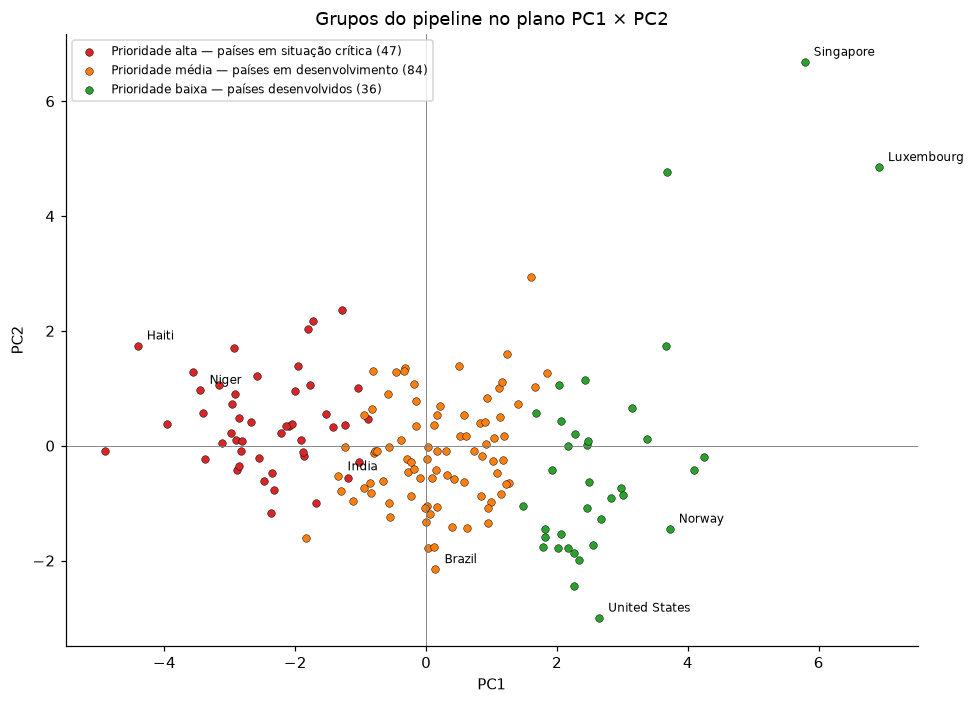

,country,child_mort,life_expec,total_fer,income,gdpp,health
1,Haiti,208.0,32.1,3.33,1500,662,6.91
2,Sierra Leone,160.0,55.0,5.20,1220,399,13.10
3,Chad,150.0,56.5,6.59,1930,897,4.53
4,Central African Republic,149.0,47.5,5.21,888,446,3.98
5,Mali,137.0,59.5,6.55,1870,708,4.98
6,Nigeria,130.0,60.5,5.84,5150,2330,5.07
7,Niger,123.0,58.8,7.49,814,348,5.16
8,Angola,119.0,60.1,6.16,5900,3530,2.85
9,Burkina Faso,116.0,57.9,5.87,1430,575,6.74
10,"Congo, Dem. Rep.",116.0,57.5,6.54,609,334,7.91


In [9]:
# Tarefas 6.1 e 6.2
# 6.1 — perfil médio de cada grupo
perfil = X.assign(grupo=grupos).groupby("grupo").mean()
perfil["n_paises"] = pd.Series(grupos).value_counts().sort_index()
display(perfil.round(2))

# Os rótulos numéricos do K-Means são arbitrários; a nomeação é feita pelo perfil
ordem = perfil["child_mort"].sort_values(ascending=False).index   # da maior para a menor mortalidade infantil
rotulos_nome = ["Prioridade alta — países em situação crítica",
                "Prioridade média — países em desenvolvimento",
                "Prioridade baixa — países desenvolvidos"]
nomes = {int(g): nome for g, nome in zip(ordem, rotulos_nome)}
print("Dicionário nomes:", nomes)

# Representação dos grupos no plano PC1 x PC2 (PCA padronizado da Parte 4)
cores = {nomes_k: c for nomes_k, c in zip(rotulos_nome, ["tab:red", "tab:orange", "tab:green"])}
fig, ax = plt.subplots(figsize=(9, 6.5))
for g, nome in nomes.items():
    sel = grupos == g
    ax.scatter(scores[sel, 0], scores[sel, 1], s=25, color=cores[nome], edgecolor="black", lw=0.3,
               label=f"{nome} ({sel.sum()})")
for i in np.where(mask)[0]:
    ax.annotate(paises.iloc[i], (scores[i, 0], scores[i, 1]), textcoords="offset points", xytext=(6, 4), fontsize=8)
ax.axhline(0, color="gray", lw=0.6)
ax.axvline(0, color="gray", lw=0.6)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("Grupos do pipeline no plano PC1 × PC2")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# 6.2 — 10 países do grupo prioritário com maior mortalidade infantil
grupo_prioritario = int(ordem[0])
top10 = (df[grupos == grupo_prioritario]
         .sort_values("child_mort", ascending=False)
         .head(10)[["country", "child_mort", "life_expec", "total_fer", "income", "gdpp", "health"]]
         .reset_index(drop=True))
top10.index = top10.index + 1
top10

**Questão 8.** Descreva cada grupo com base na tabela de perfil e indique quais países a ONG deveria priorizar, justificando com os indicadores.

**Resposta:**

| Grupo | Nº de países | Perfil médio |
|---|---|---|
| **Prioridade alta — países em situação crítica** | 47 | mortalidade infantil de 93 por mil, expectativa de vida de 59 anos, 5 filhos por mulher, renda de US$ 3.942, PIB per capita de US$ 1.922, inflação de 12% |
| **Prioridade média — países em desenvolvimento** | 84 | mortalidade infantil de 22 por mil, expectativa de vida de 73 anos, 2,3 filhos por mulher, renda de US$ 12.306, PIB per capita de US$ 6.486 |
| **Prioridade baixa — países desenvolvidos** | 36 | mortalidade infantil de 5 por mil, expectativa de vida de 80 anos, 1,75 filho por mulher, renda de US$ 45.672, PIB per capita de US$ 42.494, maior gasto em saúde (8,8% do PIB) e baixa inflação |

O grupo crítico tem mortalidade infantil **4 vezes maior** que o grupo intermediário e **18 vezes maior** que o desenvolvido, expectativa de vida 21 anos menor que a dos países desenvolvidos e renda cerca de 11 vezes menor. É formado majoritariamente por países da África Subsaariana, além de Haiti, Afeganistão e outros.

**Recomendação:** a ONG deveria concentrar os recursos no grupo de **prioridade alta** e, dentro dele, priorizar os países com pior combinação de indicadores de sobrevivência. Os 10 com maior mortalidade infantil são: **Haiti** (208 por mil e expectativa de vida de apenas 32 anos, possivelmente refletindo o terremoto de 2010), **Sierra Leone** (160), **Chad** (150), **Central African Republic** (149, com renda de US$ 888), **Mali** (137), **Nigeria** (130), **Niger** (123, com a maior fecundidade da base: 7,5 filhos por mulher), **Angola** (119), **Burkina Faso** (116) e **Congo, Dem. Rep.** (116, com a menor renda da base: US$ 609). Países como Central African Republic, Niger e Congo combinam mortalidade altíssima com renda extremamente baixa, o que sugere menor capacidade de resposta própria e maior impacto marginal de cada dólar doado. Nigéria e Angola têm renda maior (US$ 5–6 mil), o que indica que o problema ali tem mais a ver com distribuição e governança do que com escassez absoluta, e pode exigir outro tipo de intervenção.

**Questão 9.** Discuta os riscos de a ONG basear a distribuição de recursos exclusivamente neste agrupamento. Considere, entre outros aspectos: países próximos da fronteira entre grupos, a atualidade e a procedência dos dados, os indicadores escolhidos e a dificuldade de explicar decisões baseadas em componentes principais.

**Resposta:**

- **Países na fronteira entre grupos:** o K-Means atribui cada país a um único grupo, mesmo quando ele está quase equidistante de dois centroides. Na base, cerca de 10 países têm diferença menor que 0,3 entre as distâncias ao centroide mais próximo e ao segundo mais próximo (por exemplo, Botswana, Iraq, Myanmar, Solomon Islands e Micronesia). Uma pequena variação nos dados ou na semente aleatória pode mudar sua classificação e, com ela, a decisão de receber ou não recursos. Botswana e Iraq, por exemplo, saem do grupo crítico quando se usa k=4. Também há grande heterogeneidade **dentro** dos grupos: o Haiti, com 208 por mil, recebe o mesmo rótulo de países com mortalidade de 60 por mil.
- **Atualidade e procedência dos dados:** a base é do Kaggle, com dados de cerca de uma década atrás e fontes não documentadas em detalhe. Desde então ocorreram pandemia, guerras, crises econômicas e desastres naturais que mudaram profundamente a situação de muitos países. Além disso, alguns valores são suspeitos ou refletem eventos pontuais (expectativa de vida de 32 anos no Haiti, inflação de 104% na Nigéria). Decisões de US$ 10 milhões exigem dados atuais e auditáveis (Banco Mundial, OMS, UNICEF).
- **Indicadores escolhidos:** os 9 indicadores são médias nacionais e não captam desigualdade interna, conflitos armados, insegurança alimentar, acesso a água e saneamento, número de refugiados, ocorrência de desastres recentes ou a presença de outras organizações atuando no país. Alguns indicadores também medem coisas pouco relacionadas à pobreza: `exports` e `imports` dominam a PC2 e chegaram a criar um grupo inteiro só para Singapore, Luxembourg e Malta. Também não se considera o **tamanho da população**: um país pequeno e um país populoso com o mesmo perfil recebem a mesma classificação, embora o volume de pessoas afetadas seja muito diferente.
- **Explicabilidade:** componentes principais são combinações lineares abstratas de todos os indicadores. Explicar a um doador, a um governo ou a um país excluído que ele "não foi priorizado porque está no grupo 1 definido por 5 componentes principais" é difícil e pouco transparente. O resultado também depende de escolhas técnicas (padronização, número de componentes, k, semente), e a Parte 5 mostrou que mudar essas escolhas altera bastante a classificação. Decisões que afetam vidas precisam ser justificáveis em termos dos indicadores originais.
- **Recomendação:** usar o agrupamento como **ferramenta de triagem inicial**, complementada por análise individual dos países prioritários e de fronteira, dados atualizados, critérios adicionais (população, capacidade de execução local, acesso logístico) e validação por especialistas de campo.

## Parte 7 — Persistência e uso do modelo

**Tarefa 7.1.** Salve, no arquivo `modelo_paises.pkl`, um único objeto contendo o pipeline `modelo`, a lista ordenada das colunas utilizadas no treinamento e o dicionário `nomes`. Faça o download do arquivo.

**Tarefa 7.2.** Carregue o arquivo em uma nova variável e classifique os dois países hipotéticos abaixo, informando os valores **na escala original**:

| Indicador | País A | País B |
|---|---|---|
| `child_mort` | 60 | 45 |
| `exports` | 25 | 30 |
| `health` | 5,0 | 5,5 |
| `imports` | 35 | 40 |
| `income` | 5.000 | 6.000 |
| `inflation` | 8 | 7 |
| `life_expec` | 65 | 67 |
| `total_fer` | 3,5 | 3,0 |
| `gdpp` | 2.500 | 3.000 |

In [10]:
# Tarefas 7.1 e 7.2
# 7.1 — persistência de um único objeto com pipeline, colunas e nomes
artefato = {"modelo": modelo, "colunas": list(X.columns), "nomes": nomes}
joblib.dump(artefato, "modelo_paises.pkl")
print("Arquivo modelo_paises.pkl salvo.")

try:  # download automático quando executado no Google Colab
    from google.colab import files
    files.download("modelo_paises.pkl")
except ImportError:
    print("Fora do Colab: o arquivo está salvo no diretório de trabalho.")

# 7.2 — carregamento e classificação dos países hipotéticos (escala original)
carregado = joblib.load("modelo_paises.pkl")
novos = pd.DataFrame({
    "child_mort": [60, 45], "exports": [25, 30], "health": [5.0, 5.5], "imports": [35, 40],
    "income": [5000, 6000], "inflation": [8, 7], "life_expec": [65, 67], "total_fer": [3.5, 3.0],
    "gdpp": [2500, 3000],
}, index=["País A", "País B"])[carregado["colunas"]]

pred = carregado["modelo"].predict(novos)
resultado = novos.assign(grupo=pred, classificacao=[carregado["nomes"][int(g)] for g in pred])
display(resultado)

# Distância de cada país hipotético aos centroides (no espaço do pipeline)
dist = carregado["modelo"].transform(novos)
display(pd.DataFrame(dist, index=novos.index,
                     columns=[carregado["nomes"][k] for k in range(dist.shape[1])]).round(3))

Arquivo modelo_paises.pkl salvo.
Fora do Colab: o arquivo está salvo no diretório de trabalho.


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp,grupo,classificacao
País A,60,25,5.0,35,5000,8,65,3.5,2500,2,Prioridade alta — países em situação crítica
País B,45,30,5.5,40,6000,7,67,3.0,3000,1,Prioridade média — países em desenvolvimento


,Prioridade baixa — países desenvolvidos,Prioridade média — países em desenvolvimento,Prioridade alta — países em situação crítica
País A,4.419,1.798,1.602
País B,3.963,1.178,2.066


**Questão 10.** Por que foi possível informar os valores na escala original, sem padronizá-los nem aplicar o PCA manualmente? Comente também o resultado obtido para os dois países hipotéticos.

**Resposta:** Porque o objeto salvo é o **pipeline completo**, e não apenas o K-Means. O `StandardScaler` guardou a média e o desvio padrão de cada indicador calculados nos 167 países de treinamento, e o `PCA` guardou a matriz de pesos dos 5 componentes. Ao chamar `predict` com os valores na escala original, o pipeline aplica automaticamente, e na mesma ordem, as transformações aprendidas: padroniza com os parâmetros do treino, projeta nos componentes e só então calcula o centroide mais próximo. Isso evita erros como padronizar os novos dados com outra média, esquecer uma etapa ou reajustar o scaler apenas com os dois países novos (o que produziria valores sem sentido). Salvar também a lista de colunas garante que os indicadores sejam passados **na mesma ordem** usada no treinamento.

**Resultado:** o **País A** foi classificado como **prioridade alta (situação crítica)** e o **País B** como **prioridade média (em desenvolvimento)**. A diferença entre eles é pequena (mortalidade infantil de 60 contra 45, fecundidade de 3,5 contra 3,0, expectativa de vida de 65 contra 67 anos), mas foi suficiente para colocá-los em lados opostos da fronteira. As distâncias aos centroides mostram que os dois estão em zona limítrofe: o País A está a 1,60 do centroide crítico e a 1,80 do intermediário, uma margem estreita. O País B está a 1,18 do intermediário e a 2,07 do crítico. Ambos têm indicadores bem melhores que a média do grupo crítico (93 por mil), mas bem piores que a média do grupo intermediário (22 por mil). Esse é exatamente o tipo de caso discutido na Questão 9: a classificação automática deveria ser complementada por análise individual, sobretudo para o País A.

## Atividades complementares

**A.** Ajuste o pipeline com k = 4 e reconstrua a tabela de perfil. Identifique os países que formam o novo grupo e explique o que os caracteriza.

**B.** Aplique o DBSCAN sobre os dados padronizados e reduzidos pelo PCA do pipeline (`modelo[:-1].transform(X)`). Ajuste `eps` e `min_samples` de modo que no máximo 10 países sejam classificados como ruído, liste-os e explique, a partir dos indicadores originais, por que cada um é atípico.

In [11]:
# Atividade complementar A
modelo_k4 = make_pipeline(StandardScaler(), PCA(n_components=0.9, random_state=42),
                          KMeans(n_clusters=4, n_init=10, random_state=42))
grupos_k4 = modelo_k4.fit_predict(X)

perfil_k4 = X.assign(grupo=grupos_k4).groupby("grupo").mean()
perfil_k4["n_paises"] = pd.Series(grupos_k4).value_counts().sort_index()
display(perfil_k4.round(2))

print("Tabela cruzada (k=3 nas linhas, k=4 nas colunas):")
display(pd.crosstab(pd.Series(grupos, name="k=3").map(nomes), pd.Series(grupos_k4, name="k=4")))

# Novo grupo: o de k=4 que não corresponde majoritariamente a nenhum grupo de k=3 de forma única
# (identificado como o grupo de menor tamanho)
novo = int(perfil_k4["n_paises"].idxmin())
print(f"Novo grupo (k=4, rótulo {novo}) — {int(perfil_k4.loc[novo, 'n_paises'])} países:")
display(df[grupos_k4 == novo].set_index("country"))

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp,n_paises
grupo,,,,,,,,,,
0,21.91,41.30,6.28,47.92,12969.33,7.53,72.69,2.32,6885.53,89
1,4.95,45.83,9.17,39.74,45250.00,2.74,80.38,1.80,43333.33,30
2,95.11,28.60,6.30,42.31,3539.84,11.99,59.06,5.07,1766.71,45
3,4.13,176.00,6.79,156.67,64033.33,2.47,81.43,1.38,57566.67,3


Tabela cruzada (k=3 nas linhas, k=4 nas colunas):


k=4,0,1,2,3
k=3,,,,
Prioridade alta — países em situação crítica,2,0,45,0
Prioridade baixa — países desenvolvidos,3,30,0,3
Prioridade média — países em desenvolvimento,84,0,0,0


Novo grupo (k=4, rótulo 3) — 3 países:


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
country,,,,,,,,,
Luxembourg,2.8,175.0,7.77,142.0,91700,3.620,81.3,1.63,105000
Malta,6.8,153.0,8.65,154.0,28300,3.830,80.3,1.36,21100
Singapore,2.8,200.0,3.96,174.0,72100,-0.046,82.7,1.15,46600


**Análise da atividade A:** com k = 4, o grupo crítico (45 países) e o intermediário (89) praticamente se mantêm, e o grupo desenvolvido se divide. O **novo grupo** tem apenas 3 países: **Luxembourg, Malta e Singapore**. O que os caracteriza é a **abertura comercial extrema**: exportações médias de 176% e importações de 157% do PIB, contra cerca de 40–48% nos demais grupos. Também são ricos (renda média de US$ 64 mil), com mortalidade infantil baixíssima (4,1 por mil) e a maior expectativa de vida (81,4 anos). São pequenos Estados que funcionam como centros financeiros, logísticos e de reexportação, por isso aparecem no extremo da PC2. Os demais desenvolvidos (30 países) formam o grupo de alta renda "convencional". Houve ainda pequenos remanejamentos de fronteira: Botswana e Iraq saíram do grupo crítico, e Bahrain, Czech Republic e Slovak Republic saíram do grupo desenvolvido, todos indo para o grupo intermediário. Para a ONG, o quarto grupo não acrescenta informação útil: ele separa países ricos entre si, e não países necessitados.

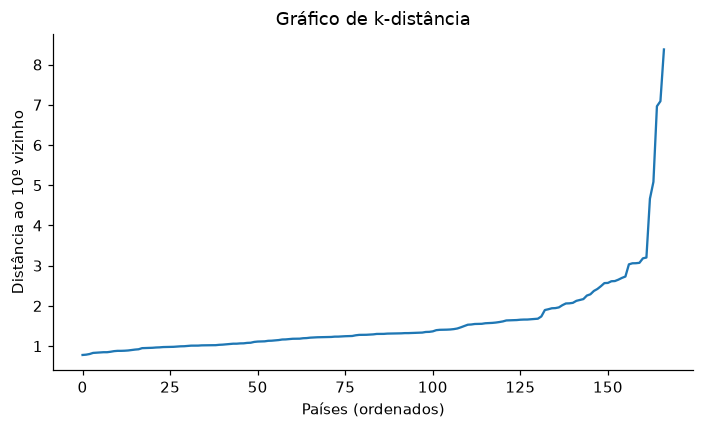

eps = 2.1, min_samples = 10
Grupos encontrados: {-1: np.int64(10), 0: np.int64(157)}

10 países classificados como ruído:


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
country,,,,,,,,,
Brunei,10.5,67.4,2.84,28.0,80600,16.700,77.1,1.84,35300
Kuwait,10.8,66.7,2.63,30.4,75200,11.200,78.2,2.21,38500
Luxembourg,2.8,175.0,7.77,142.0,91700,3.620,81.3,1.63,105000
Malta,6.8,153.0,8.65,154.0,28300,3.830,80.3,1.36,21100
Mongolia,26.1,46.7,5.44,56.7,7710,39.200,66.2,2.64,2650
Nigeria,130.0,25.3,5.07,17.4,5150,104.000,60.5,5.84,2330
Qatar,9.0,62.3,1.81,23.8,125000,6.980,79.5,2.07,70300
Singapore,2.8,200.0,3.96,174.0,72100,-0.046,82.7,1.15,46600
United States,7.3,12.4,17.90,15.8,49400,1.220,78.7,1.93,48400


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
country,,,,,,,,,
Brunei,-0.690000,0.960000,-1.450000,-0.780000,3.300000,0.850000,0.740000,-0.730000,1.220000
Kuwait,-0.680000,0.940000,-1.530000,-0.680000,3.020000,0.320000,0.860000,-0.490000,1.400000
Luxembourg,-0.880000,4.900000,0.350000,3.940000,3.880000,-0.390000,1.210000,-0.870000,5.040000
Malta,-0.780000,4.090000,0.670000,4.440000,0.580000,-0.370000,1.100000,-1.050000,0.450000
Mongolia,-0.300000,0.200000,-0.500000,0.410000,-0.490000,2.980000,-0.490000,-0.200000,-0.560000
Nigeria,2.280000,-0.580000,-0.640000,-1.220000,-0.620000,9.130000,-1.130000,1.920000,-0.580000
Qatar,-0.730000,0.780000,-1.830000,-0.960000,5.610000,-0.080000,1.010000,-0.580000,3.140000
Singapore,-0.880000,5.810000,-1.040000,5.270000,2.860000,-0.740000,1.370000,-1.190000,1.840000
United States,-0.770000,-1.050000,4.050000,-1.290000,1.680000,-0.620000,0.920000,-0.670000,1.940000


In [12]:
# Atividade complementar B
from sklearn.neighbors import NearestNeighbors

X_red = modelo[:-1].transform(X)
min_samples = 2 * X_red.shape[1]   # regra prática: 2 x número de dimensões

# Gráfico de k-distância para orientar a escolha de eps
dists, _ = NearestNeighbors(n_neighbors=min_samples).fit(X_red).kneighbors(X_red)
kdist = np.sort(dists[:, -1])
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(kdist)
ax.set_xlabel("Países (ordenados)")
ax.set_ylabel(f"Distância ao {min_samples}º vizinho")
ax.set_title("Gráfico de k-distância")
plt.tight_layout()
plt.show()

# Busca do menor eps que deixa no máximo 10 países como ruído
for eps in np.arange(0.5, 4.01, 0.05):
    rot = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_red)
    if (rot == -1).sum() <= 10:
        break
eps = round(float(eps), 2)
rot_dbscan = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_red)
print(f"eps = {eps}, min_samples = {min_samples}")
print("Grupos encontrados:", dict(pd.Series(rot_dbscan).value_counts().sort_index()))

ruido = df[rot_dbscan == -1].set_index("country")
print(f"\n{len(ruido)} países classificados como ruído:")
display(ruido)

# z-scores dos países atípicos: indicam quais indicadores são extremos
z = pd.DataFrame(X_pad, columns=X.columns, index=paises)
display(z.loc[ruido.index].round(2).style.background_gradient(cmap="RdBu_r", vmin=-4, vmax=4))

**Análise da atividade B:** com `min_samples = 10` (2 × 5 dimensões) e `eps = 2,1` (menor valor da busca que deixa no máximo 10 pontos como ruído), o DBSCAN encontrou um único grupo denso com 157 países e **10 países classificados como ruído**. Isso confirma que os países não formam grupos naturalmente separados: há um contínuo, com alguns pontos isolados. Motivos de cada país ser atípico, segundo os indicadores originais:

| País | Por que é atípico |
|---|---|
| **Singapore** | exportações (200%) e importações (174%) do PIB são os máximos da base; também tem a menor fecundidade da base (1,15) e uma das maiores expectativas de vida (82,7) |
| **Luxembourg** | PIB per capita máximo (US$ 105 mil), renda de US$ 91,7 mil e comércio exterior de 175% (exportações) e 142% (importações) do PIB |
| **Malta** | comércio exterior extremo (exportações de 153% e importações de 154% do PIB) com renda apenas moderada (US$ 28 mil), combinação incomum |
| **Qatar** | renda máxima da base (US$ 125 mil) e menor gasto com saúde (1,81% do PIB) |
| **Brunei** | renda muito alta (US$ 80,6 mil) com inflação elevada (16,7%) e gasto baixo com saúde (2,84%), perfil de economia petroleira |
| **Kuwait** | renda muito alta (US$ 75 mil), inflação de 11,2% e gasto baixo com saúde (2,63%), também petroleiro |
| **United States** | gasto com saúde máximo da base (17,9% do PIB) e comércio exterior muito baixo (exportações de 12,4% e importações de 15,8%) para um país rico |
| **Nigeria** | inflação máxima da base (104%) combinada com mortalidade infantil altíssima (130 por mil) e fecundidade de 5,8 |
| **Venezuela** | inflação muito alta (45,9%) em um país de renda média, com comércio exterior baixo |
| **Mongolia** | inflação de 39,2% em país de renda média-baixa |

Os atípicos são de dois tipos: **extremos de riqueza e comércio exterior** (centros financeiros e países petroleiros) e **extremos de inflação** (Nigeria, Venezuela e Mongolia). Nenhum deles é atípico por pobreza. Os países mais pobres são numerosos e semelhantes entre si, por isso formam uma região densa e não aparecem como ruído.